# 02 — Data Loading and Inspection

## Loan Default Risk Classification


## 1. Imports and Configuration


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Display settings
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.width', 200)

# Plot settings
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
warnings.filterwarnings('ignore', category=FutureWarning)

# Paths
RAW_PATH = '../../data/raw/loan_dataset.xlsx'
FIGURES_PATH = '../../outputs/figures/'
TABLES_PATH = '../../outputs/tables/'

print('Imports loaded successfully.')

Imports loaded successfully.


## 2. Load the Raw Dataset


In [2]:
# Load the main data sheet
df = pd.read_excel(RAW_PATH, sheet_name='Loan_Data')

print(f'Dataset loaded successfully.')
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')

Dataset loaded successfully.
Shape: 10,100 rows x 41 columns


### 3.1 Basic Dimensions


In [3]:
print(f'Number of rows (applicants):  {df.shape[0]:,}')
print(f'Number of columns (variables): {df.shape[1]}')

Number of rows (applicants):  10,100
Number of columns (variables): 41


### 3.2 Column Names and Pandas Data Types


In [4]:
# Display all columns with their pandas-inferred dtype
dtype_df = pd.DataFrame({
    'Column': df.columns,
    'Pandas_Dtype': df.dtypes.values,
    'Non_Null': df.notnull().sum().values,
    'Null': df.isnull().sum().values,
    'Null_Pct': (df.isnull().sum().values / len(df) * 100).round(2)
})
dtype_df.index = range(1, len(dtype_df) + 1)
dtype_df.index.name = '#'
print(dtype_df.to_string())

                           Column    Pandas_Dtype  Non_Null  Null  Null_Pct
#                                                                          
1                    Applicant_ID             str     10100     0      0.00
2                Application_Date  datetime64[us]     10100     0      0.00
3                     Branch_Code             str     10100     0      0.00
4             Application_Channel             str     10100     0      0.00
5                             Age           int64     10100     0      0.00
6                          Gender             str     10100     0      0.00
7                  Marital_Status             str      9996   104      1.03
8                 Education_Level             str      9715   385      3.81
9                      Dependents           int64     10100     0      0.00
10                         Region             str     10100     0      0.00
11                Residence_Years         float64      9716   384      3.80
12          

### 3.3 First Five Rows (Transposed for Readability)


In [5]:
df.head().T

,0,1,2,3,4
Applicant_ID,LN-114369,LN-136223,LN-103022,LN-107320,LN-129811
Application_Date,2023-12-18 00:00:00,2022-11-12 00:00:00,2022-11-01 00:00:00,2022-11-22 00:00:00,2023-06-30 00:00:00
Branch_Code,BR-01,BR-20,BR-01,BR-05,BR-03
Application_Channel,Branch,Online,Online,Online,Branch
Age,57,45,63,51,34
Gender,Female,Male,Female,Female,Male
Marital_Status,NaN,Married,Married,Married,Married
Education_Level,Master,Diploma,Bachelor,High School,Diploma
Dependents,2,2,1,0,1
Region,Rural,Rural,Rural,Urban,Suburban


### 3.4 Last Five Rows


In [6]:
df.tail().T

,10095,10096,10097,10098,10099
Applicant_ID,LN-109055,LN-128165,LN-150816,LN-136401,LN-126426
Application_Date,2022-11-13 00:00:00,2024-01-25 00:00:00,2023-02-14 00:00:00,2024-07-15 00:00:00,2024-04-10 00:00:00
Branch_Code,BR-39,BR-06,BR-01,BR-05,BR-01
Application_Channel,Branch,Branch,Online,Branch,Online
Age,46,66,62,54,39
Gender,Male,Male,Female,Female,Male
Marital_Status,Single,Married,Divorced,Divorced,Married
Education_Level,High School,Diploma,Diploma,Bachelor,Bachelor
Dependents,0,0,0,2,0
Region,Rural,Rural,Suburban,Rural,Urban


### 3.5 Variable Inventory & Role Classification


In [7]:
# ── Variable inventory ──
inventory = pd.DataFrame({
    'Column': [
        'Applicant_ID', 'Application_Date', 'Branch_Code', 'Application_Channel',
        'Age', 'Gender', 'Marital_Status', 'Education_Level', 'Dependents', 'Region',
        'Residence_Years', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
        'Years_Employed', 'Annual_Income', 'Salary_Account_With_Bank', 'Vehicle_Owned',
        'Loan_Purpose', 'Loan_Amount', 'Loan_Term_Months', 'Interest_Rate_Pct',
        'Property_Value', 'Has_Co_Applicant', 'Credit_Score', 'Credit_History_Years',
        'Existing_Loans', 'Total_Credit_Limit', 'Credit_Utilization_Pct',
        'Credit_Inquiries_6M', 'Late_Payments_2Y', 'Months_Since_Last_Delinquency',
        'Previous_Default', 'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
        'Overdrafts_12M', 'Bank_Relationship_Years', 'Mobile_Banking_User',
        'Loan_Default', 'Risk_Category'
    ],
    'Variable_Type': [
        'Identifier', 'Date', 'Categorical (nominal)', 'Categorical (nominal)',
        'Numeric (continuous)', 'Categorical (nominal)', 'Categorical (nominal)',
        'Ordinal', 'Numeric (integer/count)', 'Categorical (nominal)',
        'Numeric (continuous)', 'Categorical (nominal)', 'Categorical (nominal)',
        'Categorical (nominal)', 'Numeric (continuous)', 'Numeric (continuous)',
        'Binary', 'Binary',
        'Categorical (nominal)', 'Numeric (continuous)', 'Numeric (integer/count)',
        'Numeric (continuous)', 'Numeric (continuous)', 'Binary',
        'Numeric (continuous)', 'Numeric (continuous)',
        'Numeric (integer/count)', 'Numeric (continuous)', 'Numeric (continuous)',
        'Numeric (integer/count)', 'Numeric (integer/count)', 'Numeric (continuous)',
        'Binary', 'Numeric (continuous)', 'Numeric (continuous)', 'Numeric (continuous)',
        'Numeric (integer/count)', 'Numeric (continuous)', 'Binary',
        'Target (binary)', 'Target (multiclass ordinal)'
    ],
    'Role': [
        'Identifier', 'Feature (engineer)', 'Feature', 'Feature',
        'Feature', 'Feature / Protected', 'Feature', 'Feature', 'Feature',
        'Feature / Protected',
        'Feature', 'Feature', 'Feature', 'Feature',
        'Feature', 'Feature', 'Feature', 'Feature',
        'Feature', 'Feature', 'Feature', 'Feature',
        'Feature (structural blank)', 'Feature', 'Feature', 'Feature',
        'Feature', 'Feature', 'Feature',
        'Feature', 'Feature', 'Feature (structural blank)',
        'Feature', 'Feature', 'Feature', 'Feature',
        'Feature', 'Feature', 'Feature',
        'Target', 'Target'
    ],
    'Description': [
        'Unique application reference (not sequential)',
        'Date of application (2022-2024)',
        'Originating branch (40 levels)',
        'Branch / Online / Agent',
        'Applicant age in years (contains data-entry errors)',
        'Male / Female (recorded inconsistently)',
        'Single / Married / Divorced / Widowed',
        'High School < Diploma < Bachelor < Master < PhD',
        'Number of financial dependents (0-5)',
        'Urban / Suburban / Rural',
        'Years at current address',
        'Rent / Mortgage / Own',
        'Salaried / Self-Employed / Contract / Unemployed / Retired',
        'Sector of employer (typing variants exist)',
        'Years in current employment',
        'Gross annual income',
        'Whether salary is paid into this bank',
        'Whether applicant owns a vehicle',
        'Home / Auto / Education / Business / Medical / Personal',
        'Requested loan amount',
        'Loan term: 12, 24, 36, 48, 60, or 84 months',
        'Annual interest rate offered (unit inconsistencies)',
        'Only filled for Home loans (structural blank)',
        'Whether application is joint',
        'Bureau credit score 300-850 (sentinel 9999 exists)',
        'Length of credit history in years',
        'Number of open loans (0-6)',
        'Sum of approved credit limits',
        'Share of revolving credit used (%)',
        'Hard credit enquiries in last 6 months',
        'Late payments in last 24 months',
        'Blank when no late payments (structural blank)',
        'Whether applicant defaulted on a previous loan',
        'Existing monthly debt service payment',
        'Savings balance (some entries are text N/A)',
        'Current account balance (can be negative = overdrawn)',
        'Overdraft events in last 12 months',
        'Years as a customer of this bank',
        'Whether applicant uses mobile banking app',
        'Did the borrower default? (Yes/No, positive=Yes)',
        'Internal risk grade (Low/Medium/High)'
    ]
})

inventory.index = range(1, len(inventory) + 1)
inventory.index.name = '#'
print(inventory.to_string())

                           Column                Variable_Type                        Role                                                 Description
#                                                                                                                                                     
1                    Applicant_ID                   Identifier                  Identifier               Unique application reference (not sequential)
2                Application_Date                         Date          Feature (engineer)                             Date of application (2022-2024)
3                     Branch_Code        Categorical (nominal)                     Feature                              Originating branch (40 levels)
4             Application_Channel        Categorical (nominal)                     Feature                                     Branch / Online / Agent
5                             Age         Numeric (continuous)                     Feature    

### 3.6 Variable Type Summary Counts


In [8]:
# Count variable types
type_counts = inventory['Variable_Type'].value_counts().reset_index()
type_counts.columns = ['Variable_Type', 'Count']
type_counts['Percentage'] = (type_counts['Count'] / len(inventory) * 100).round(1)
type_counts = type_counts.sort_values('Count', ascending=False).reset_index(drop=True)
print(type_counts.to_string(index=False))
print(f'\nTotal: {type_counts["Count"].sum()} columns')

              Variable_Type  Count  Percentage
       Numeric (continuous)     16        39.0
      Categorical (nominal)      9        22.0
    Numeric (integer/count)      6        14.6
                     Binary      5        12.2
                 Identifier      1         2.4
                       Date      1         2.4
                    Ordinal      1         2.4
            Target (binary)      1         2.4
Target (multiclass ordinal)      1         2.4

Total: 41 columns


### 4.1 Target 1: Loan_Default Distribution


In [9]:
# Value counts and percentages
ld_counts = df['Loan_Default'].value_counts()
ld_pct = df['Loan_Default'].value_counts(normalize=True) * 100

ld_summary = pd.DataFrame({
    'Count': ld_counts,
    'Percentage': ld_pct.round(2)
})
ld_summary.index.name = 'Loan_Default'
print('=== Loan_Default Distribution ===')
print(ld_summary)
print(f'\nDefault rate: {ld_pct["Yes"]:.2f}%')
print(f'Imbalance ratio (No:Yes): {ld_counts["No"] / ld_counts["Yes"]:.1f}:1')

=== Loan_Default Distribution ===
              Count  Percentage
Loan_Default                   
No             8098       80.18
Yes            2002       19.82

Default rate: 19.82%
Imbalance ratio (No:Yes): 4.0:1


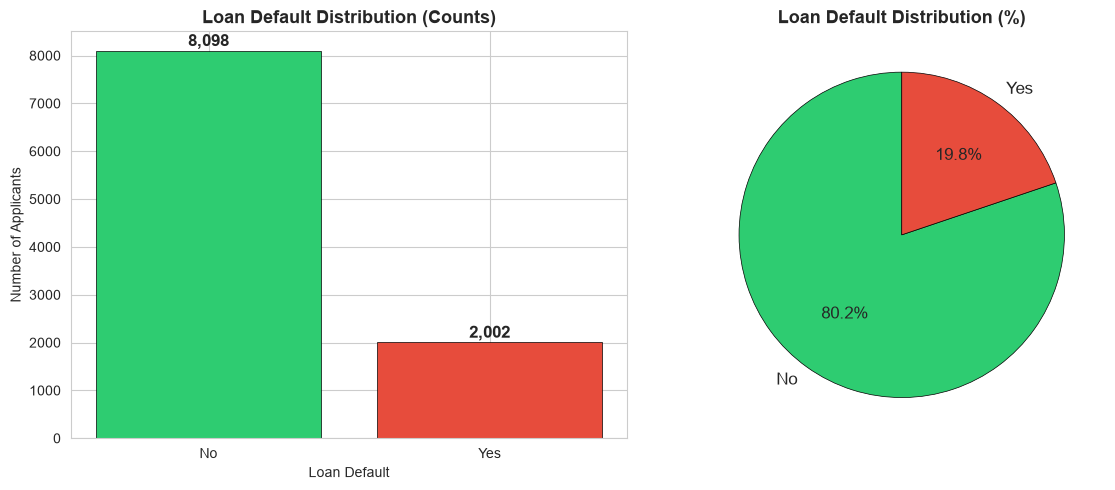

In [10]:
# Visualise Loan_Default distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Count plot
colors_ld = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(ld_counts.index, ld_counts.values, color=colors_ld, edgecolor='black', linewidth=0.5)
axes[0].set_title('Loan Default Distribution (Counts)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Loan Default')
axes[0].set_ylabel('Number of Applicants')
for bar, count in zip(bars, ld_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f'{count:,}', ha='center', fontsize=12, fontweight='bold')

# Percentage pie chart
axes[1].pie(ld_counts.values, labels=ld_counts.index, autopct='%1.1f%%',
            colors=colors_ld, startangle=90, textprops={'fontsize': 12},
            wedgeprops={'edgecolor': 'black', 'linewidth': 0.5})
axes[1].set_title('Loan Default Distribution (%)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{FIGURES_PATH}default_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.2 Target 2: Risk_Category Distribution


In [11]:
# Value counts and percentages
rc_counts = df['Risk_Category'].value_counts()
rc_pct = df['Risk_Category'].value_counts(normalize=True) * 100

# Reorder as Low, Medium, High
rc_order = ['Low', 'Medium', 'High']
rc_counts = rc_counts.reindex(rc_order)
rc_pct = rc_pct.reindex(rc_order)

rc_summary = pd.DataFrame({
    'Count': rc_counts,
    'Percentage': rc_pct.round(2)
})
rc_summary.index.name = 'Risk_Category'
print('=== Risk_Category Distribution ===')
print(rc_summary)

=== Risk_Category Distribution ===
               Count  Percentage
Risk_Category                   
Low             5059       50.09
Medium          3024       29.94
High            2017       19.97


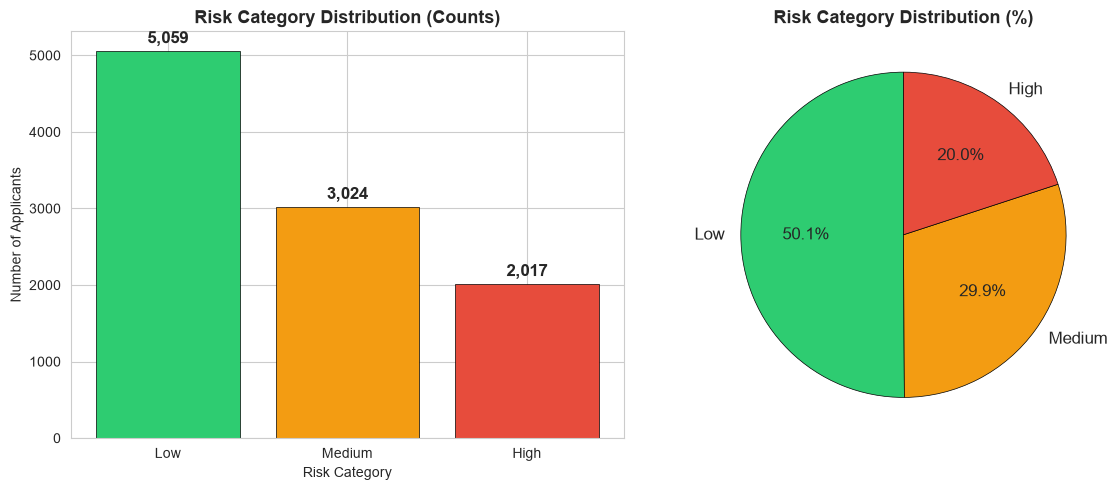

In [12]:
# Visualise Risk_Category distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors_rc = ['#2ecc71', '#f39c12', '#e74c3c']
bars = axes[0].bar(rc_order, rc_counts.values, color=colors_rc, edgecolor='black', linewidth=0.5)
axes[0].set_title('Risk Category Distribution (Counts)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Risk Category')
axes[0].set_ylabel('Number of Applicants')
for bar, count in zip(bars, rc_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f'{count:,}', ha='center', fontsize=12, fontweight='bold')

axes[1].pie(rc_counts.values, labels=rc_order, autopct='%1.1f%%',
            colors=colors_rc, startangle=90, textprops={'fontsize': 12},
            wedgeprops={'edgecolor': 'black', 'linewidth': 0.5})
axes[1].set_title('Risk Category Distribution (%)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{FIGURES_PATH}risk_category_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.3 Target Cross-Tabulation (`Loan_Default` x `Risk_Category`)


In [13]:
# Cross-tabulation to investigate the relationship between the two targets
crosstab = pd.crosstab(df['Loan_Default'], df['Risk_Category'],
                       margins=True, margins_name='Total')
crosstab = crosstab[['Low', 'Medium', 'High', 'Total']]
print('=== Cross-tab: Loan_Default x Risk_Category (Counts) ===')
print(crosstab)
print()

# Percentage within each Risk_Category
crosstab_pct = pd.crosstab(df['Loan_Default'], df['Risk_Category'], normalize='columns') * 100
crosstab_pct = crosstab_pct[['Low', 'Medium', 'High']].round(1)
print('=== Default Rate (%) within each Risk Category ===')
print(crosstab_pct)

=== Cross-tab: Loan_Default x Risk_Category (Counts) ===
Risk_Category   Low  Medium  High  Total
Loan_Default                            
No             4966    2507   625   8098
Yes              93     517  1392   2002
Total          5059    3024  2017  10100

=== Default Rate (%) within each Risk Category ===
Risk_Category   Low  Medium  High
Loan_Default                     
No             98.2    82.9  31.0
Yes             1.8    17.1  69.0


## 5. Feature Exclusion Analysis


In [14]:
# Feature exclusion table
exclusion_data = [
    ['Applicant_ID', 'Exclude', 'Identifier',
     'Unique row ID with no predictive value. Including it would let the model memorise individual applicants.', 'None'],
    ['Application_Date', 'Exclude (raw)', 'Date variable',
     'Raw dates are not meaningful features. Engineer month, year, or quarter instead.', 'Low'],
    ['Risk_Category', 'Exclude', 'Target leakage',
     'Internal risk grade almost perfectly reveals Loan_Default. Including it would inflate performance unrealistically.', 'Critical'],
    ['Loan_Default', 'N/A', 'Is the target',
     'This is the target variable for binary classification.', 'N/A'],
    ['Branch_Code', 'Keep (encode carefully)', 'High cardinality',
     '40 levels. One-hot encoding creates 39 columns. Consider frequency or target encoding inside CV.', 'Low'],
    ['Application_Channel', 'Keep', 'Legitimate feature',
     'Available at application time. Standard categorical feature.', 'None'],
    ['Age', 'Keep (clean first)', 'Legitimate feature',
     'Contains impossible values (3, 118, 212). Clean before use.', 'None'],
    ['Gender', 'Keep (investigate fairness)', 'Protected attribute',
     'Available at application time. Use but check fairness implications.', 'Low (proxy)'],
    ['Marital_Status', 'Keep (impute missing)', 'Legitimate feature',
     '104 missing values. Available at application time.', 'None'],
    ['Education_Level', 'Keep (impute missing)', 'Ordinal feature',
     '385 missing. Encode ordinally.', 'None'],
    ['Dependents', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Region', 'Keep (investigate fairness)', 'Protected attribute',
     'Available at application time. Use but check fairness implications.', 'Low (proxy)'],
    ['Residence_Years', 'Keep (impute)', 'Legitimate feature', '384 missing.', 'None'],
    ['Home_Ownership', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Employment_Type', 'Keep (clean labels)', 'Legitimate feature',
     'Inconsistent labels. Standardise before use.', 'None'],
    ['Employer_Sector', 'Keep (clean labels)', 'Legitimate feature',
     'Typing variants. Standardise before use.', 'None'],
    ['Years_Employed', 'Keep (clean + impute)', 'Legitimate feature',
     '530 missing. Contains negative values (impossible). Clean first.', 'None'],
    ['Annual_Income', 'Keep (impute)', 'Legitimate feature',
     '466 missing. Right-skewed. Consider log transform.', 'None'],
    ['Salary_Account_With_Bank', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Vehicle_Owned', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Loan_Purpose', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Loan_Amount', 'Keep', 'Legitimate feature', 'No issues. Right-skewed.', 'None'],
    ['Loan_Term_Months', 'Keep', 'Legitimate feature', 'Discrete: 12/24/36/48/60/84.', 'None'],
    ['Interest_Rate_Pct', 'Keep (fix units)', 'Legitimate feature',
     '8 values are fractions (<1) instead of percentages. Multiply by 100.', 'None'],
    ['Property_Value', 'Keep (handle structural blank)', 'Legitimate but structurally blank',
     'Blank for non-Home loans (82% missing). Create Is_Home_Loan flag; compute LTV for Home loans only.', 'None'],
    ['Has_Co_Applicant', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Credit_Score', 'Keep (clean sentinel)', 'Legitimate feature',
     '285 missing + 6 sentinel values of 9999. Replace 9999 with NaN.', 'None'],
    ['Credit_History_Years', 'Keep (impute)', 'Legitimate feature', '315 missing.', 'None'],
    ['Existing_Loans', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Total_Credit_Limit', 'Keep (impute)', 'Legitimate feature', '312 missing.', 'None'],
    ['Credit_Utilization_Pct', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Credit_Inquiries_6M', 'Keep (impute)', 'Legitimate feature', '201 missing.', 'None'],
    ['Late_Payments_2Y', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Months_Since_Last_Delinquency', 'Keep (handle structural blank)', 'Legitimate but structurally blank',
     'Blank when no late payments (72% missing). Create Ever_Delinquent flag; fill with 0.', 'None'],
    ['Previous_Default', 'Keep', 'Legitimate feature',
     'Whether applicant defaulted before. Available at decision time.', 'Low'],
    ['Monthly_Debt_Payment', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Savings_Balance', 'Keep (convert N/A)', 'Legitimate feature',
     'Text N/A entries. Convert to NaN then impute.', 'None'],
    ['Checking_Balance', 'Keep (impute)', 'Legitimate feature',
     'Can be negative (overdrawn). Valid. 273 missing.', 'None'],
    ['Overdrafts_12M', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Bank_Relationship_Years', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
    ['Mobile_Banking_User', 'Keep', 'Legitimate feature', 'No issues.', 'None'],
]

exclusion_df = pd.DataFrame(exclusion_data,
    columns=['Column', 'Decision', 'Reason_Category', 'Details', 'Leakage_Risk'])
exclusion_df.index = range(1, len(exclusion_df) + 1)

# Show full table
pd.set_option('display.max_colwidth', 100)
print(exclusion_df.to_string())
pd.set_option('display.max_colwidth', 60)  # Reset

                           Column                        Decision                    Reason_Category                                                                                                             Details Leakage_Risk
1                    Applicant_ID                         Exclude                         Identifier            Unique row ID with no predictive value. Including it would let the model memorise individual applicants.         None
2                Application_Date                   Exclude (raw)                      Date variable                                    Raw dates are not meaningful features. Engineer month, year, or quarter instead.          Low
3                   Risk_Category                         Exclude                     Target leakage  Internal risk grade almost perfectly reveals Loan_Default. Including it would inflate performance unrealistically.     Critical
4                    Loan_Default                             N/A               

In [15]:
# Summary: columns to exclude
excluded = exclusion_df[exclusion_df['Decision'].str.startswith('Exclude')]
print('=== Columns to EXCLUDE when predicting Loan_Default ===')
print()
for _, row in excluded.iterrows():
    print(f"  {row['Column']:30s} -> {row['Reason_Category']}")
    print(f"  {'':30s}    {row['Details']}")
    print()
print(f'Total excluded: {len(excluded)} columns')
print(f'Remaining potential features: {41 - len(excluded) - 1} columns')  # -1 for target itself

=== Columns to EXCLUDE when predicting Loan_Default ===

  Applicant_ID                   -> Identifier
                                    Unique row ID with no predictive value. Including it would let the model memorise individual applicants.

  Application_Date               -> Date variable
                                    Raw dates are not meaningful features. Engineer month, year, or quarter instead.

  Risk_Category                  -> Target leakage
                                    Internal risk grade almost perfectly reveals Loan_Default. Including it would inflate performance unrealistically.

Total excluded: 3 columns
Remaining potential features: 37 columns


In [16]:
# Save tables for later reference
inventory.to_csv(f'{TABLES_PATH}variable_inventory.csv', index=True)
exclusion_df.to_csv(f'{TABLES_PATH}feature_exclusion_table.csv', index=True)

### 6.1 Unique Values per Column


In [17]:
# Count unique values for each column
unique_df = pd.DataFrame({
    'Column': df.columns,
    'Unique_Values': [df[col].nunique() for col in df.columns],
    'Includes_NaN': [df[col].isnull().any() for col in df.columns],
    'Sample_Values': [str(df[col].dropna().unique()[:5].tolist()) for col in df.columns]
})
unique_df.index = range(1, len(unique_df) + 1)
print(unique_df.to_string())

                           Column  Unique_Values  Includes_NaN                                                                                                                                                               Sample_Values
1                    Applicant_ID          10000         False                                                                                                           ['LN-114369', 'LN-136223', 'LN-103022', 'LN-107320', 'LN-129811']
2                Application_Date           1090         False  [Timestamp('2023-12-18 00:00:00'), Timestamp('2022-11-12 00:00:00'), Timestamp('2022-11-01 00:00:00'), Timestamp('2022-11-22 00:00:00'), Timestamp('2023-06-30 00:00:00')]
3                     Branch_Code             40         False                                                                                                                               ['BR-01', 'BR-20', 'BR-05', 'BR-03', 'BR-02']
4             Application_Channel              3         Fal

### 6.2 Numeric Variables — Summary Statistics


In [18]:
# Descriptive stats for numeric columns
print(df.describe().T.to_string())

                                 count                        mean                  min                  25%                  50%                  75%                  max           std
Application_Date                 10100  2023-06-24 15:02:55.366336  2022-01-03 00:00:00  2022-09-26 18:00:00  2023-06-21 00:00:00  2024-03-21 00:00:00  2024-12-27 00:00:00           NaN
Age                            10100.0                    43.44495                  3.0                 35.0                 42.0                 50.0                212.0     10.767803
Dependents                     10100.0                    1.152772                  0.0                  0.0                  1.0                  2.0                  5.0      1.042197
Residence_Years                 9716.0                    7.616087                  0.2                  3.8                  6.6                 10.3                 37.2      5.006325
Years_Employed                  9570.0                    8.415193    

### 6.3 Categorical Variables — Value Counts


In [19]:
# Check categorical columns for inconsistent labels
cat_cols = ['Gender', 'Marital_Status', 'Education_Level', 'Application_Channel',
            'Region', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
            'Loan_Purpose', 'Salary_Account_With_Bank', 'Vehicle_Owned',
            'Has_Co_Applicant', 'Previous_Default', 'Mobile_Banking_User']

for col in cat_cols:
    print(f'=== {col} ({df[col].nunique()} unique) ===')
    print(df[col].value_counts(dropna=False).to_string())
    print()

=== Gender (8 unique) ===
Gender
Male       5199
Female     4221
M           195
F           138
male        124
female      100
MALE         75
Female       48

=== Marital_Status (4 unique) ===
Marital_Status
Married     5886
Single      2482
Divorced    1203
Widowed      425
NaN          104

=== Education_Level (5 unique) ===
Education_Level
Bachelor       3140
High School    2725
Diploma        2127
Master         1314
PhD             409
NaN             385

=== Application_Channel (3 unique) ===
Application_Channel
Branch    4548
Online    3817
Agent     1735

=== Region (3 unique) ===
Region
Urban       5036
Suburban    3051
Rural       2013

=== Home_Ownership (3 unique) ===
Home_Ownership
Mortgage    3683
Rent        3444
Own         2973

=== Employment_Type (8 unique) ===
Employment_Type
Salaried         5585
Self-Employed    1795
Contract         1447
Unemployed        634
Retired           320
Self employed     157
self-employed      87
salaried           75

=== Employer